# ASMSA v2 &mdash; Quickstart

[Setup](01-setup.ipynb) &#8594;

| | |
|---|---|
| **What it does** | The whole idea in one notebook: featurize a protein-ligand trajectory, train the autoencoder, read the latent space, recover the binding poses. |
| **Typical runtime** | about 2 minutes on a laptop CPU |
| **Needs** | nothing &mdash; it generates its own synthetic complex |
| **Produces** | a trained model in memory, and plots |

---

This notebook is the 60-second version of the pipeline, on synthetic data, so you can
see what ASMSA produces before investing in your own system. It is **not** a substitute
for the numbered notebooks: it skips the train/validation split, hyperparameter tuning,
PLUMED export and the MD run.

When you are ready to use your own trajectory, start at [01-setup](01-setup.ipynb).

## 1. A synthetic complex

A 12-residue peptide with a slow breathing mode, plus a 5-atom ligand that occupies
**two distinct binding poses** and switches between them. We know the ground truth, so
at the end we can check whether the model actually found it.

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import mdtraj as md

import asmsa_v2 as asmsa
from asmsa_v2.demo import make_demo_complex
from asmsa_v2.viz import use_asmsa_style

use_asmsa_style()
asmsa.set_seed(0)

demo = make_demo_complex('demo_data', n_residues=12, n_frames=3000, seed=0)
traj = md.load(str(demo.traj), top=str(demo.conf))
print(demo.summary())

DemoSystem: 12 residues + 5-atom ligand = 65 atoms, 3000 frames
  conformation : demo_data/complex.pdb
  trajectory   : demo_data/complex.xtc
  mock topology: demo_data/topology.gro
  ground truth : 2 binding poses (1896 / 1104 frames) + 1 slow breathing mode


## 2. Featurize

The autoencoder never sees Cartesian coordinates &mdash; those depend on how the molecule
happens to be oriented. It sees **internal coordinates**: bond lengths, angles, dihedrals
within each component, plus **inter-component distances**, which are what encode the
binding pose.

In [3]:
protein = traj.top.select('not resname LIG')
ligand = traj.top.select('resname LIG')

# intra-component geometry along the peptide backbone
backbone = traj.top.select('name N CA C')
bonds = np.array([[backbone[i], backbone[i + 1]] for i in range(len(backbone) - 1)])
angles = np.array([backbone[i:i + 3] for i in range(len(backbone) - 2)])
diheds = np.array([backbone[i:i + 4] for i in range(len(backbone) - 3)])

cm = asmsa.ComplexMolecule(
    n_atoms=traj.n_atoms,
    components={'protein': protein, 'ligand': ligand},
    bonds=bonds, angles=angles, diheds=diheds,
    inter_subsets={'protein': traj.top.select('name CA'),
                   'ligand': ligand},
    inter_mode='dense',
)
X = asmsa.featurize_frames(traj.xyz, cm.get_model())
print(f'{X.shape[0]} frames x {X.shape[1]} features')

3000 frames x 195 features


### Why the features must be standardized

Feature blocks live on wildly different scales. A covalent bond length barely moves;
an inter-component distance swings by nanometres. An unweighted reconstruction loss
therefore *only sees the widest block* &mdash; the stiff internal geometry becomes
invisible to the model.

**What to look for:** a max/min spread ratio in the tens or hundreds, and a variance
share bar chart dominated by one block. That is the problem; standardizing is the fix.

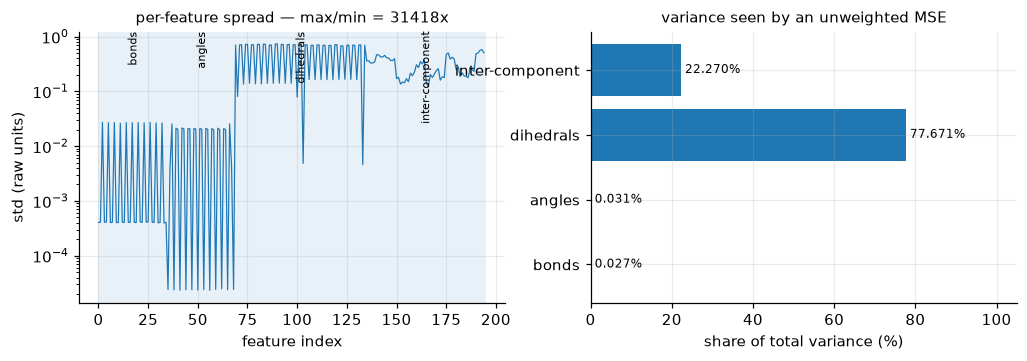

FeatureScaler(method='standard', n_features=195)
  constant features clamped to scale=1: 0
  raw per-feature std: min=1.8798e-05 max=0.7351 (ratio 39105x)
  raw variance share by block:
    bonds              0.027%   (std 0.0087123 avg over 35 features)
    angles             0.031%   (std 0.01271 avg over 34 features)
    dihedrals         77.671%   (std 0.51517 avg over 66 features)
    inter-component   22.270%   (std 0.30307 avg over 60 features)


In [4]:
n_inter = X.shape[1] - (len(bonds) + len(angles) + 2 * len(diheds))
blocks = {
    'bonds': (0, len(bonds)),
    'angles': (len(bonds), len(bonds) + len(angles)),
    'dihedrals': (len(bonds) + len(angles), X.shape[1] - n_inter),
    'inter-component': (X.shape[1] - n_inter, X.shape[1]),
}
asmsa.viz.feature_scale_report(X.numpy(), blocks=blocks)
plt.show()

scaler = asmsa.FeatureScaler().fit(X)
Xs = scaler.transform(X)
print(scaler.report(X.numpy(), feature_blocks=blocks))

## 3. Train

`latent_reg='mmd'` matches the latent distribution to the prior with a Wasserstein
autoencoder penalty instead of a discriminator: no minimax game to balance, and it is
markedly less prone to collapsing a 2-D latent onto a line. Switch to
`latent_reg='adversarial'` for the classic AAE.

epoch 1/40:   0%|          | 0/23 [00:00<?, ?batch/s]

epoch 2/40:   0%|          | 0/23 [00:00<?, ?batch/s]

epoch 3/40:   0%|          | 0/23 [00:00<?, ?batch/s]

epoch 4/40:   0%|          | 0/23 [00:00<?, ?batch/s]

epoch 5/40:   0%|          | 0/23 [00:00<?, ?batch/s]

...

epoch 36/40:   0%|          | 0/23 [00:00<?, ?batch/s]

epoch 37/40:   0%|          | 0/23 [00:00<?, ?batch/s]

epoch 38/40:   0%|          | 0/23 [00:00<?, ?batch/s]

epoch 39/40:   0%|          | 0/23 [00:00<?, ?batch/s]

epoch 40/40:   0%|          | 0/23 [00:00<?, ?batch/s]

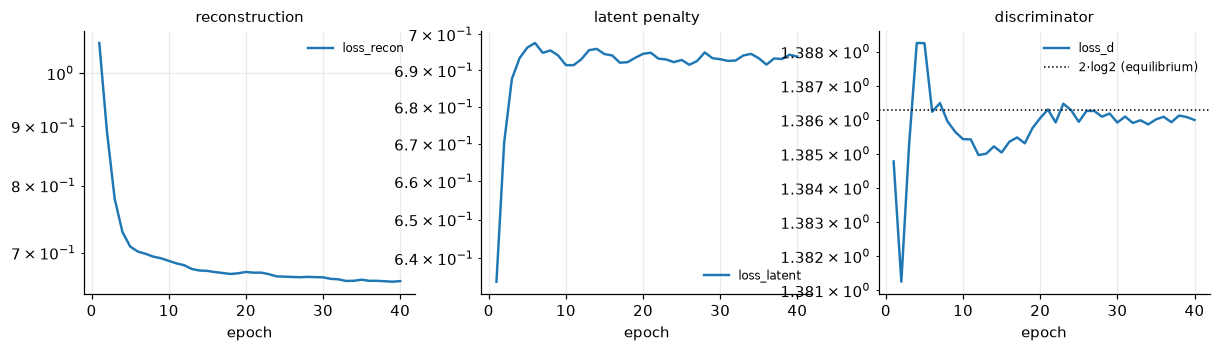

In [9]:
ds = asmsa.MultiMolDataset({'complex': Xs})

model = asmsa.AAE(feature_dims=ds.feature_dims, latent_dim=2)
trainer = asmsa.Trainer(
    model,
    prior=asmsa.IsotropicNormalPrior(2),
    config=asmsa.TrainConfig(epochs=40, batch_size=128,
                             latent_reg='adversarial', lam_latent=10.0,
                             restore_best=False, seed=0),
)
history = trainer.fit(ds.loader(batch_size=128))

asmsa.viz.training_curves(history)
plt.show()

## 4. Read the latent space

Each frame becomes one point in a 2-D plane. The free-energy surface is
`-kT ln P(z)`: dark basins are populated states, light regions are rarely visited.

**What to look for:** two separated basins, matching the two binding poses we built in.
The right-hand panel colours by the ground truth, so the two should line up.

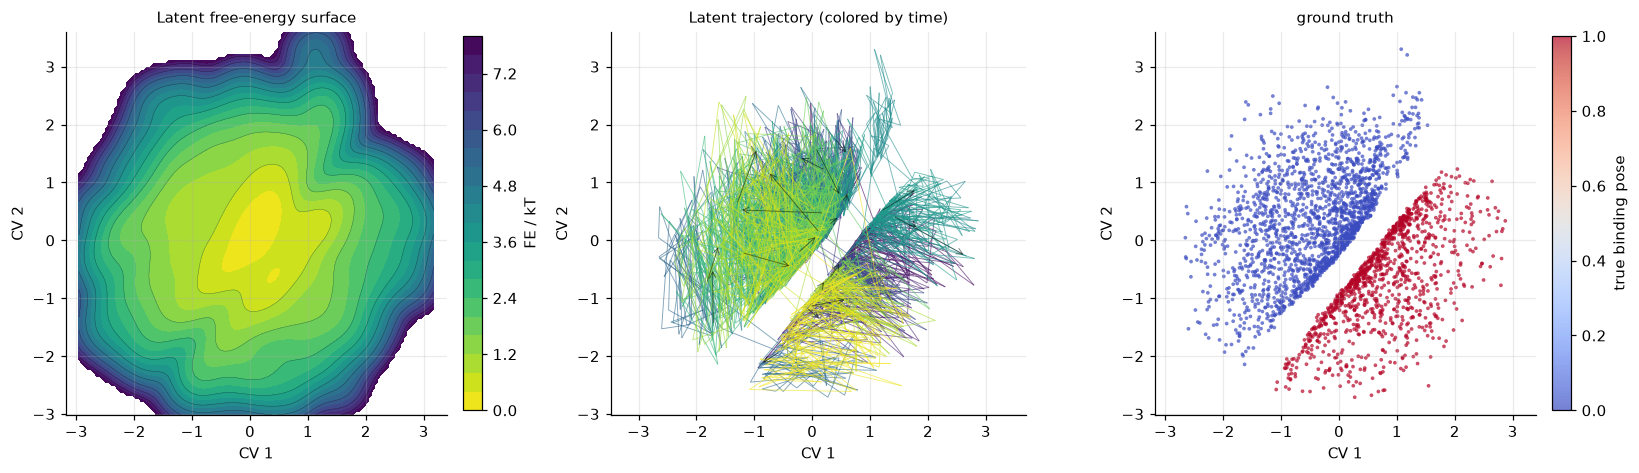

In [10]:
z = trainer.encode_all({'complex': Xs})['complex'].numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
asmsa.viz.free_energy_surface(z, ax=axes[0])
asmsa.viz.latent_trajectory(z, ax=axes[1], arrow_every=150)
asmsa.viz.latent_colored_by(z, demo.true_pose, ax=axes[2], cmap='coolwarm',
                            cbar_label='true binding pose',
                            title='ground truth')
for a in axes:
    asmsa.viz.latent_axes(a)
plt.tight_layout(); plt.show()

## 5. Recover the binding poses

HDBSCAN finds the basins without being told how many there are, and marks sparsely
populated frames as noise (`-1`) rather than forcing them into a cluster.

The **adjusted Rand index** below compares the discovered clusters with the ground-truth
poses: `1.0` means a perfect match. This is the number that tells you the pipeline worked.

In [11]:
result = asmsa.cluster_latent(z, min_cluster_size=80)
print(result.summary())

try:
    from sklearn.metrics import adjusted_rand_score
    keep = result.labels >= 0
    ari = adjusted_rand_score(demo.true_pose[keep], result.labels[keep])
    print(f'\nadjusted Rand index vs ground truth: {ari:.3f}  '
          f'(1.0 = the clusters are exactly the true poses)')
except ImportError:
    print('install scikit-learn to score the clustering')

[hdbscan] 2 cluster(s)
  cluster   0:   643 frames, rep=frame 730, centroid=(+0.65, -0.42)
  cluster   1:  1379 frames, rep=frame 1930, centroid=(-0.27, +0.25)
  noise:          978 frames

adjusted Rand index vs ground truth: 1.000  (1.0 = the clusters are exactly the true poses)


## 6. Is this model any good?

Four questions, four numbers. See [04-train](04-train.ipynb) for what to do about a
`poor` verdict on any of them.

In [12]:
report = asmsa.evaluate_latent(
    z,
    x=Xs.numpy(),
    x_recon=trainer.reconstruct_all({'complex': Xs})['complex'].numpy(),
    prior=asmsa.IsotropicNormalPrior(2),
    vamp_lag=20,
)
report

metric,value,verdict,meaning
reconstruction (relative MSE),0.657,poor,fraction of standardized feature variance left unexplained; 1.0 = no better than predicting the mean
"prior match (KL, nats)",0.391,ok,k-NN KL between prior and latent samples; v1 treated < 0.5-0.7 as acceptable
slow dynamics (VAMP-2 @ lag 20),1.648 / 3,ok,"how much of the slow subspace the latent resolves; higher is better, max is 1 + latent_dim"
usable spread (effective dim),1.99 / 2,good,participation ratio of latent variance; well below latent_dim means the latent collapsed to a lower-dimensional manifold


## What this quickstart skipped

| Skipped | Why it matters | Where it is done |
|---|---|---|
| train/validation split | without it you cannot tell memorization from generalization, and early stopping has no signal | [02-prepare](02-prepare.ipynb) |
| hyperparameter tuning | architecture and the prior-matching weight change results a lot | [03-tune](03-tune.ipynb) |
| TorchScript + `plumed.dat` export | this is what turns the latent into usable collective variables | [05-plumed](05-plumed.ipynb) |
| biased MD and free energies | the point of learning CVs is to sample with them | [06-md](06-md.ipynb) |

Also note the data here is a **geometric mock**, not a force-field simulation. Never draw
physical conclusions from it.

---

**Next: [Setup](01-setup.ipynb)** &#8594;